# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Putu Ayu Dinda Pramiswari
- **Email:** ds014b6x1449@student.devacademy.id
- **ID Dicoding:** DS014B6X1449

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks bisnis:** Dataset berisi catatan penyewaan sepeda *Capital Bikeshare* di Washington D.C. (1 Januari 2011 – 31 Desember 2012). Bayangkan kita adalah tim analis operator bike sharing yang ingin menentukan **kapan armada harus ditambah, kapan promosi paling efektif, dan kapan pemeliharaan sebaiknya dilakukan**.

- **Pertanyaan 1:** Berapa rata-rata jumlah penyewaan sepeda per hari pada setiap musim dan kondisi cuaca sepanjang tahun 2011–2012, serta berapa persen selisih antara kondisi dengan rata-rata tertinggi dan terendah?
  - *Specific*: fokus pada musim dan cuaca terhadap penyewaan harian. *Measurable*: rata-rata penyewaan per hari dan selisih persen. *Action-oriented*: menentukan musim/cuaca untuk penambahan armada, promosi, dan pemeliharaan. *Relevant*: permintaan sangat dipengaruhi lingkungan. *Time-bound*: 2011–2012.
- **Pertanyaan 2:** Pada jam berapa puncak penyewaan sepeda terjadi pada hari kerja dibandingkan akhir pekan/hari libur sepanjang tahun 2011–2012, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut?
  - *Specific*: pola jam pada dua tipe hari. *Measurable*: jam puncak dan rata-rata penyewaan per jam. *Action-oriented*: penjadwalan redistribusi sepeda, staf, dan jam promosi. *Relevant*: ketersediaan sepeda di jam sibuk menentukan kepuasan pengguna. *Time-bound*: 2011–2012.
- **Pertanyaan 3:** Berapa persen pertumbuhan total penyewaan sepeda tahun 2012 dibandingkan 2011 (Year-over-Year), dan pada bulan apa pertumbuhan tertinggi serta puncak penyewaan terjadi?
  - *Specific*: pertumbuhan tahunan per bulan. *Measurable*: total penyewaan dan persen pertumbuhan. *Action-oriented*: perencanaan kapasitas armada dan anggaran. *Relevant*: pertumbuhan adalah indikator utama kesehatan bisnis. *Time-bound*: 2012 vs 2011.

## Import Semua Packages/Library yang Digunakan

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="white")

# Palet warna : abu-abu sebagai dasar, biru untuk sorotan, oranye sebagai pembanding
BASE, HIGHLIGHT, ACCENT = "#B8C4D0", "#1F6FB2", "#E07B00"

## Data Wrangling

In [44]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Gathering Data

#### Load day_df (data harian) dan hour_df (data per jam)

In [45]:
day_df = pd.read_csv("/content/drive/MyDrive/submission/data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [46]:
hour_df = pd.read_csv("/content/drive/MyDrive/submission/data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi **731 baris x 16 kolom** (satu baris per hari, 1 Januari 2011 – 31 Desember 2012), sedangkan `hour_df` berisi **17.379 baris x 17 kolom** (satu baris per jam) dengan tambahan kolom `hr`.
- Kolom `cnt` adalah total penyewaan (`casual` + `registered`) dan menjadi variabel utama analisis.
- Fitur cuaca (`temp`, `atemp`, `hum`, `windspeed`) masih berupa nilai ternormalisasi, dan kolom kategorik masih berupa kode angka.

### Assessing Data

#### Identifying missing value dan duplicate data

In [47]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [48]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [49]:
print("Missing value day_df  :", day_df.isna().sum().sum())
print("Duplikat day_df       :", day_df.duplicated().sum())
print("Missing value hour_df :", hour_df.isna().sum().sum())
print("Duplikat hour_df      :", hour_df.duplicated().sum())

Missing value day_df  : 0
Duplikat day_df       : 0
Missing value hour_df : 0
Duplikat hour_df      : 0


#### Identifying missing records (jam yang tidak tercatat) pada hour_df

In [50]:
expected_rows = len(day_df) * 24
print(f"Jumlah baris seharusnya (731 hari x 24 jam): {expected_rows:,}")
print(f"Jumlah baris aktual hour_df                : {len(hour_df):,}")
print(f"Jam yang tidak tercatat                    : {expected_rows - len(hour_df):,}")

jam_per_hari = hour_df.groupby("dteday").size()
print("Jumlah hari dengan catatan jam tidak lengkap:", (jam_per_hari < 24).sum())

# Apakah total penyewaan harian di hour_df sama dengan day_df?
cek = (hour_df.groupby("dteday")["cnt"].sum().reset_index()
       .merge(day_df[["dteday", "cnt"]], on="dteday", suffixes=("_hour", "_day")))
print("Total harian hour_df == day_df:", (cek["cnt_hour"] == cek["cnt_day"]).all())

Jumlah baris seharusnya (731 hari x 24 jam): 17,544
Jumlah baris aktual hour_df                : 17,379
Jam yang tidak tercatat                    : 165
Jumlah hari dengan catatan jam tidak lengkap: 76
Total harian hour_df == day_df: True


**Steps to Take:**
- Missing value dan duplikat tidak ditemukan, sehingga tidak perlu penanganan khusus.
- Jam yang tidak tercatat dilengkapi dengan membuat kerangka data lengkap (tanggal x 24 jam). Karena total harian `hour_df` identik dengan `day_df`, jam yang hilang berarti **tidak ada penyewaan (cnt = 0)**. Kolom cuaca pada jam tersebut diisi dari jam terdekat di hari yang sama.

#### Identifying inconsistent value dan tipe data yang tidak sesuai

In [51]:
print("Tipe data kolom dteday:", day_df["dteday"].dtype)
print("Contoh nilai          :", day_df["dteday"].head(3).tolist())

Tipe data kolom dteday: object
Contoh nilai          : ['2011-01-01', '2011-01-02', '2011-01-03']


In [52]:
# Readme dataset: 1 = springer, 2 = summer, 3 = fall, 4 = winter. Mari cek terhadap tanggal sebenarnya.
tmp = day_df.assign(dteday=pd.to_datetime(day_df["dteday"]))
cek_musim = tmp.groupby("season").agg(
    bulan=("mnth", lambda s: sorted(s.unique())),
    tanggal_awal_2011=("dteday", lambda s: s[s.dt.year == 2011].min().date()),
)
cek_musim

,bulan,tanggal_awal_2011
season,,
1,"[1, 2, 3, 12]",2011-01-01
2,"[3, 4, 5, 6]",2011-03-21
3,"[6, 7, 8, 9]",2011-06-21
4,"[9, 10, 11, 12]",2011-09-23


In [53]:
print("Nilai weathersit day_df :", day_df["weathersit"].value_counts().sort_index().to_dict())
print("Nilai weathersit hour_df:", hour_df["weathersit"].value_counts().sort_index().to_dict())

Nilai weathersit day_df : {1: 463, 2: 247, 3: 21}
Nilai weathersit hour_df: {1: 11413, 2: 4544, 3: 1419, 4: 3}


**Steps to Take:**
- Kolom `dteday` bertipe `object` (string) sehingga harus diubah ke `datetime`.
- Label musim pada readme tidak konsisten dengan tanggal sebenarnya: musim 1 mencakup Desember-Maret (**Winter**), musim 2 dimulai 21 Maret (**Spring**), musim 3 dimulai 21 Juni (**Summer**), dan musim 4 dimulai 23 September (**Fall**). Label akan diperbaiki mengikuti kalender musim yang sebenarnya.
- Kolom kategorik berupa kode angka (`season`, `weathersit`, `weekday`, `yr`, `workingday`) diubah menjadi label yang mudah dibaca.
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` berupa nilai ternormalisasi, sehingga dikembalikan ke satuan asli (°C, %, km/jam) agar mudah diinterpretasikan.

#### Identifying invalid value (kelembapan dan kecepatan angin bernilai 0)

In [54]:
print("hum == 0 | hour_df:", (hour_df["hum"] == 0).sum(), "jam | day_df:", (day_df["hum"] == 0).sum(), "hari")
print("Tanggal dengan hum == 0 :", sorted(hour_df.loc[hour_df["hum"] == 0, "dteday"].unique()))

n_wind0 = (hour_df["windspeed"] == 0).sum()
print(f"windspeed == 0 | hour_df: {n_wind0:,} jam ({n_wind0 / len(hour_df):.1%}) | day_df: {(day_df['windspeed'] == 0).sum()} hari")

hum == 0 | hour_df: 22 jam | day_df: 1 hari
Tanggal dengan hum == 0 : ['2011-03-10']
windspeed == 0 | hour_df: 2,180 jam (12.5%) | day_df: 0 hari


**Steps to Take:**
- Kelembapan 0% tidak masuk akal secara fisik (terjadi seharian pada 10 Maret 2011) sehingga dianggap data sensor yang tidak valid. Nilainya diganti dengan interpolasi linear dari nilai sekitarnya.
- Kecepatan angin 0 muncul pada sekitar 12% jam, padahal pada `day_df` tidak pernah ada hari dengan angin 0. Ini mengindikasikan sensor tidak merekam. Nilai 0 diganti dengan kecepatan angin harian dari `day_df`.

#### Identifying outlier

In [55]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

kolom = ["cnt", "casual", "registered", "temp", "hum", "windspeed"]
pd.DataFrame({"day_df": {c: count_outliers(day_df[c]) for c in kolom},
              "hour_df": {c: count_outliers(hour_df[c]) for c in kolom}})

,day_df,hour_df
cnt,0,505
casual,44,1192
registered,0,680
temp,0,0
hum,2,22
windspeed,13,342


In [56]:
# Hari dengan penyewaan paling rendah
day_df.nsmallest(3, "cnt")[["dteday", "weathersit", "hum", "windspeed", "cnt"]]

,dteday,weathersit,hum,windspeed,cnt
667,2012-10-29,3,0.880000,0.358200,22
26,2011-01-27,1,0.687500,0.113837,431
725,2012-12-26,3,0.823333,0.316546,441


**Steps to Take:**
- Outlier terdeteksi pada `casual`, `windspeed`, dan jumlah penyewaan per jam. Setelah dicek, nilai-nilai tersebut **valid secara bisnis**: puncak jam sibuk, hari libur cerah, atau hari ekstrem seperti 29 Oktober 2012 (hanya 22 penyewaan, bertepatan dengan Badai Sandy).
- Outlier **tidak dihapus** karena justru memuat informasi penting untuk perencanaan operasional.

**Ringkasan masalah dan tindakan pada tahap Cleaning Data:**

| No | Masalah | Jenis masalah | Tindakan |
|---|---|---|---|
| 1 | `dteday` bertipe string | Tipe data tidak sesuai | Ubah ke `datetime` |
| 2 | Label musim pada readme tidak sesuai tanggal | Nilai tidak akurat / tidak konsisten | Beri label berdasarkan rentang tanggal sebenarnya |
| 3 | 165 jam tidak tercatat di `hour_df` | Data tidak lengkap | Lengkapi kerangka tanggal x 24 jam, isi penyewaan dengan 0 |
| 4 | Kelembapan = 0% (10 Maret 2011) | Nilai tidak valid | Ubah ke NaN lalu interpolasi linear |
| 5 | Kecepatan angin = 0 pada 12,5% jam | Nilai tidak valid / tidak akurat | Ganti dengan kecepatan angin harian dari `day_df` |
| 6 | Kode angka dan nilai ternormalisasi | Nilai tidak informatif | Beri label kategori dan kembalikan ke satuan asli |
| 7 | Outlier `casual`, `windspeed`, dan penyewaan per jam | Outlier | Dipertahankan karena valid secara bisnis |

**Insight:**
- Tidak ada missing value maupun data duplikat, tetapi ditemukan **6 masalah kualitas data** lain:
  1. `dteday` bertipe string, bukan tanggal.
  2. Label musim pada readme tidak konsisten dengan tanggal sebenarnya (musim 1 = Winter, bukan "springer").
  3. Kolom kategorik berupa kode angka dan fitur cuaca masih ternormalisasi.
  4. **165 jam tidak tercatat** pada `hour_df` (tersebar di 76 hari); karena total harian identik dengan `day_df`, jam tersebut berarti tidak ada penyewaan.
  5. Kelembapan = 0% (22 jam, seluruhnya pada 10 Maret 2011) dan kecepatan angin = 0 (2.180 jam, 12,5%) yang tidak realistis.
  6. Outlier pada `casual`, `windspeed`, dan penyewaan per jam, namun semuanya valid secara bisnis sehingga dipertahankan.

### Cleaning Data

#### Fixing tipe data

In [57]:
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

print(day_df["dteday"].dtype, "|", hour_df["dteday"].dtype)

datetime64[ns] | datetime64[ns]


#### Fixing missing records pada hour_df

In [58]:
# Kerangka lengkap: setiap tanggal x 24 jam
full_idx = pd.MultiIndex.from_product([day_df["dteday"], range(24)], names=["dteday", "hr"])
hour_full = hour_df.set_index(["dteday", "hr"]).reindex(full_idx).reset_index()

# Kolom turunan tanggal diambil dari day_df
date_cols = ["season", "yr", "mnth", "holiday", "weekday", "workingday"]
hour_full = hour_full.drop(columns=date_cols).merge(day_df[["dteday"] + date_cols], on="dteday", how="left")

# Jam yang tidak tercatat = tidak ada penyewaan
count_cols = ["casual", "registered", "cnt"]
hour_full[count_cols] = hour_full[count_cols].fillna(0).astype(int)

# Cuaca pada jam yang hilang diisi dari jam terdekat di hari yang sama
weather_cols = ["weathersit", "temp", "atemp", "hum", "windspeed"]
hour_full[weather_cols] = hour_full.groupby("dteday")[weather_cols].transform(lambda s: s.ffill().bfill())

print(f"Baris sebelum: {len(hour_df):,} -> sesudah: {len(hour_full):,}")
print("Total penyewaan tetap sama:", hour_df["cnt"].sum() == hour_full["cnt"].sum())

Baris sebelum: 17,379 -> sesudah: 17,544
Total penyewaan tetap sama: True


#### Fixing invalid value (hum = 0 dan windspeed = 0)

In [59]:
# Kelembapan 0 -> NaN -> interpolasi linear berdasarkan urutan waktu
day_df["hum"] = day_df["hum"].replace(0, np.nan).interpolate(limit_direction="both")
hour_full["hum"] = hour_full["hum"].replace(0, np.nan).interpolate(limit_direction="both")

# Kecepatan angin 0 pada data per jam -> diganti kecepatan angin harian dari day_df
hour_full = hour_full.merge(day_df[["dteday", "windspeed"]].rename(columns={"windspeed": "windspeed_day"}),
                            on="dteday", how="left")
mask = hour_full["windspeed"] == 0
hour_full.loc[mask, "windspeed"] = hour_full.loc[mask, "windspeed_day"]
hour_full = hour_full.drop(columns="windspeed_day")

print("hum == 0 tersisa       :", (hour_full["hum"] == 0).sum() + (day_df["hum"] == 0).sum())
print("windspeed == 0 tersisa :", (hour_full["windspeed"] == 0).sum())

hum == 0 tersisa       : 0
windspeed == 0 tersisa : 0


#### Fixing inconsistent value: label kategorik dan satuan

In [60]:
SEASON_MAP = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
WEATHER_MAP = {1: "Cerah", 2: "Berkabut", 3: "Hujan Ringan", 4: "Hujan Lebat"}
WEEKDAY_MAP = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

def ordered_cat(series, mapping):
    return pd.Categorical(series.astype(int).map(mapping), categories=list(mapping.values()), ordered=True)

def standardize(df):
    out = df.copy()
    out["season"] = ordered_cat(out["season"], SEASON_MAP)
    out["weather"] = ordered_cat(out["weathersit"], WEATHER_MAP)
    out["weekday"] = ordered_cat(out["weekday"], WEEKDAY_MAP)
    out["day_type"] = np.where(out["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    out["year"] = out["yr"].map({0: 2011, 1: 2012})
    # Kembalikan nilai ternormalisasi ke satuan asli (sesuai readme dataset)
    out["temp_c"] = out["temp"] * 41
    out["atemp_c"] = out["atemp"] * 50
    out["hum_pct"] = out["hum"] * 100
    out["windspeed_kmh"] = out["windspeed"] * 67
    out = out.rename(columns={"dteday": "date", "mnth": "month", "hr": "hour"})
    urutan = ["date", "year", "month", "hour", "season", "weekday", "day_type", "weather",
              "temp_c", "atemp_c", "hum_pct", "windspeed_kmh", "casual", "registered", "cnt"]
    return out[[c for c in urutan if c in out.columns]]

day_df = standardize(day_df)
hour_df = standardize(hour_full)
day_df["weather"] = day_df["weather"].cat.remove_unused_categories()   # day_df tidak memiliki cuaca 'Hujan Lebat'

day_df.head()

,date,year,month,season,weekday,day_type,weather,temp_c,atemp_c,hum_pct,windspeed_kmh,casual,registered,cnt
0,2011-01-01,2011,1,Winter,Sabtu,Akhir Pekan/Libur,Berkabut,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2011-01-02,2011,1,Winter,Minggu,Akhir Pekan/Libur,Berkabut,14.902598,17.68695,69.6087,16.652113,131,670,801
2,2011-01-03,2011,1,Winter,Senin,Hari Kerja,Cerah,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,2011-01-04,2011,1,Winter,Selasa,Hari Kerja,Cerah,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,2011-01-05,2011,1,Winter,Rabu,Hari Kerja,Cerah,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [61]:
hour_df.head()

,date,year,month,hour,season,weekday,day_type,weather,temp_c,atemp_c,hum_pct,windspeed_kmh,casual,registered,cnt
0,2011-01-01,2011,1,0,Winter,Sabtu,Akhir Pekan/Libur,Cerah,9.84,14.395,81.0,10.749882,3,13,16
1,2011-01-01,2011,1,1,Winter,Sabtu,Akhir Pekan/Libur,Cerah,9.02,13.635,80.0,10.749882,8,32,40
2,2011-01-01,2011,1,2,Winter,Sabtu,Akhir Pekan/Libur,Cerah,9.02,13.635,80.0,10.749882,5,27,32
3,2011-01-01,2011,1,3,Winter,Sabtu,Akhir Pekan/Libur,Cerah,9.84,14.395,75.0,10.749882,3,10,13
4,2011-01-01,2011,1,4,Winter,Sabtu,Akhir Pekan/Libur,Cerah,9.84,14.395,75.0,10.749882,0,1,1


#### Menyiapkan main_data.csv untuk dashboard

In [62]:
# Dashboard memakai data per jam, ditambah label cuaca harian dari day_df
main_df = hour_df.merge(day_df[["date", "weather"]].rename(columns={"weather": "weather_day"}),
                        on="date", how="left")
main_df.to_csv("/content/drive/MyDrive/submission/dashboard/main_data.csv", index=False)

print("Ukuran main_df :", main_df.shape)
print("Missing value  :", main_df.isna().sum().sum())
print("Rentang tanggal:", main_df["date"].min().date(), "s.d.", main_df["date"].max().date())

Ukuran main_df : (17544, 16)
Missing value  : 0
Rentang tanggal: 2011-01-01 s.d. 2012-12-31


**Insight:**
- Seluruh masalah pada tahap Assessing telah ditangani: `date` bertipe datetime, label musim/cuaca/hari sudah informatif, satuan cuaca kembali ke °C, % dan km/jam, serta tidak ada lagi nilai kelembapan atau angin yang bernilai 0.
- Data per jam kini lengkap **17.544 baris (731 hari x 24 jam)** dan total penyewaan tetap sama (**3.292.679**), sehingga pembersihan tidak mengubah jumlah transaksi.
- `main_data.csv` (data per jam yang sudah bersih + label cuaca harian) menjadi sumber data dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif data harian

In [63]:
day_df[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed_kmh"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,windspeed_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


### Explore penyewaan harian berdasarkan musim dan cuaca

In [64]:
season_stats = (day_df.groupby("season", observed=False)["cnt"]
                .agg(jumlah_hari="count", rata_rata="mean", median="median", total="sum").round(0))
season_stats

,jumlah_hari,rata_rata,median,total
season,,,,
Winter,181,2604.0,2209.0,471348
Spring,184,4992.0,4942.0,918589
Summer,188,5644.0,5354.0,1061129
Fall,178,4728.0,4634.0,841613


In [65]:
weather_stats = (day_df.groupby("weather", observed=True)["cnt"]
                 .agg(jumlah_hari="count", rata_rata="mean", median="median").round(0))
weather_stats

,jumlah_hari,rata_rata,median
weather,,,
Cerah,463,4877.0,4844.0
Berkabut,247,4036.0,4040.0
Hujan Ringan,21,1803.0,1817.0


In [66]:
# Kombinasi musim x cuaca (rata-rata penyewaan per hari)
day_df.pivot_table(index="season", columns="weather", values="cnt", aggfunc="mean", observed=False).round(0)

weather,Cerah,Berkabut,Hujan Ringan
season,,,
Winter,2811.0,2357.0,935.0
Spring,5549.0,4237.0,1169.0
Summer,5878.0,5222.0,2752.0
Fall,5044.0,4654.0,1962.0


In [67]:
# Apakah pola pengaruh cuaca konsisten di kedua tahun?
by_year = day_df.pivot_table(index="year", columns="weather", values="cnt", aggfunc="mean", observed=True).round(0)
by_year["turun_berkabut_%"] = ((1 - by_year["Berkabut"] / by_year["Cerah"]) * 100).round(0)
by_year["turun_hujan_%"] = ((1 - by_year["Hujan Ringan"] / by_year["Cerah"]) * 100).round(0)
by_year

weather,Cerah,Berkabut,Hujan Ringan,turun_berkabut_%,turun_hujan_%
year,,,,,
2011,3695.0,3088.0,1674.0,16.0,55.0
2012,6004.0,4991.0,2126.0,17.0,65.0


In [68]:
# Selisih persen antara kondisi tertinggi dan terendah
for nama, s in [("Musim", season_stats["rata_rata"]), ("Cuaca", weather_stats["rata_rata"])]:
    tinggi, rendah = s.idxmax(), s.idxmin()
    print(f"{nama}: tertinggi = {tinggi} ({s[tinggi]:,.0f}/hari), terendah = {rendah} ({s[rendah]:,.0f}/hari) "
          f"-> {tinggi} lebih tinggi {s[tinggi] / s[rendah] - 1:.0%} dari {rendah}; {rendah} {1 - s[rendah] / s[tinggi]:.0%} lebih rendah")

Musim: tertinggi = Summer (5,644/hari), terendah = Winter (2,604/hari) -> Summer lebih tinggi 117% dari Winter; Winter 54% lebih rendah
Cuaca: tertinggi = Cerah (4,877/hari), terendah = Hujan Ringan (1,803/hari) -> Cerah lebih tinggi 170% dari Hujan Ringan; Hujan Ringan 63% lebih rendah


In [69]:
# Korelasi faktor cuaca dengan jumlah penyewaan harian
day_df[["temp_c", "hum_pct", "windspeed_kmh", "cnt"]].corr()["cnt"].drop("cnt").round(2)

,cnt
temp_c,0.63
hum_pct,-0.12
windspeed_kmh,-0.23


### Explore pola penyewaan per jam: hari kerja vs akhir pekan/libur

In [70]:
hourly = hour_df.groupby(["day_type", "hour"])["cnt"].mean().unstack(0).round(0)
hourly.T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Akhir Pekan/Libur,90.0,69.0,52.0,25.0,8.0,8.0,19.0,43.0,106.0,172.0,...,365.0,359.0,353.0,324.0,280.0,231.0,174.0,141.0,116.0,86.0
Hari Kerja,36.0,16.0,8.0,5.0,5.0,25.0,102.0,288.0,473.0,240.0,...,183.0,201.0,293.0,524.0,490.0,347.0,249.0,186.0,138.0,88.0


In [71]:
for tipe in hourly.columns:
    s = hourly[tipe]
    print(f"{tipe}: jam puncak {s.idxmax():02d}:00 dengan rata-rata {s.max():,.0f} penyewaan/jam")
    if tipe == "Hari Kerja":
        pagi, sore = s[s.index < 12], s[s.index >= 12]
        print(f"   puncak pagi {pagi.idxmax():02d}:00 ({pagi.max():,.0f}) | puncak sore {sore.idxmax():02d}:00 ({sore.max():,.0f})")

Akhir Pekan/Libur: jam puncak 13:00 dengan rata-rata 373 penyewaan/jam
Hari Kerja: jam puncak 17:00 dengan rata-rata 524 penyewaan/jam
   puncak pagi 08:00 (473) | puncak sore 17:00 (524)


In [72]:
# Komposisi pengguna casual vs registered per tipe hari (rata-rata per hari)
user_mix = day_df.groupby("day_type")[["casual", "registered", "cnt"]].mean().round(0)
user_mix["persen_casual"] = (user_mix["casual"] / user_mix["cnt"] * 100).round(1)
user_mix

,casual,registered,cnt,persen_casual
day_type,,,,
Akhir Pekan/Libur,1371.0,2959.0,4330.0,31.7
Hari Kerja,607.0,3978.0,4585.0,13.2


### Explore pertumbuhan penyewaan bulanan 2011 vs 2012

In [73]:
monthly = day_df.groupby(["year", "month"])["cnt"].sum().unstack(0)
monthly["pertumbuhan_yoy_%"] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly

year,2011,2012,pertumbuhan_yoy_%
month,,,
1,38189,96744,153.3
2,48215,103137,113.9
3,64045,164875,157.4
4,94870,174224,83.6
5,135821,195865,44.2
6,143512,202830,41.3
7,141341,203607,44.1
8,136691,214503,56.9
9,127418,218573,71.5


In [74]:
total = day_df.groupby("year")["cnt"].sum()
print(f"Total 2011: {total[2011]:,} | Total 2012: {total[2012]:,} | Pertumbuhan YoY: {total[2012] / total[2011] - 1:.1%}")
print("Bulan pertumbuhan tertinggi :", monthly["pertumbuhan_yoy_%"].idxmax(), f"({monthly['pertumbuhan_yoy_%'].max():.0f}%)")
print("Bulan puncak 2012           :", monthly[2012].idxmax(), f"({monthly[2012].max():,} penyewaan)")
print("Bulan terendah 2012         :", monthly[2012].idxmin(), f"({monthly[2012].min():,} penyewaan)")

Total 2011: 1,243,103 | Total 2012: 2,049,576 | Pertumbuhan YoY: 64.9%
Bulan pertumbuhan tertinggi : 3 (157%)
Bulan puncak 2012           : 9 (218,573 penyewaan)
Bulan terendah 2012         : 1 (96,744 penyewaan)


**Insight:**
- Rata-rata penyewaan harian **4.504** (median 4.548) dengan rentang sangat lebar, **22 sampai 8.714**, sehingga permintaan sangat dipengaruhi faktor eksternal.
- **Musim:** Summer 5.644/hari, Spring 4.992, Fall 4.728, Winter 2.604. **Cuaca:** Cerah 4.877/hari, Berkabut 4.036, Hujan Ringan 1.803 (hanya 21 hari; cuaca "Hujan Lebat" hanya muncul 3 jam sehingga tidak ada pada data harian).
- Urutan cuaca selalu sama di semua musim (Cerah > Berkabut > Hujan Ringan). Hujan ringan di Summer (2.752) bahkan hampir sama dengan hari cerah di Winter (2.811).
- Pola pengaruh cuaca **konsisten di kedua tahun**: cuaca berkabut menurunkan penyewaan 16% (2011) dan 17% (2012), sedangkan hujan ringan menurunkannya 55% (2011) dan 65% (2012).
- Suhu berkorelasi positif kuat dengan penyewaan (**+0,63**), sedangkan kecepatan angin (-0,23) dan kelembapan (-0,12) berkorelasi negatif lemah.
- **Pola jam:** hari kerja punya dua puncak, **08:00 (473)** dan **17:00 (524)**; akhir pekan/libur punya satu puncak pada **13:00 (373)**.
- Pengguna *casual* mencapai **31,7%** penyewaan pada akhir pekan/libur, dibanding hanya **13,2%** pada hari kerja, sehingga hari kerja didominasi pengguna terdaftar (komuter).
- **Pertumbuhan:** total 2011 = 1.243.103 dan 2012 = 2.049.576 (**+64,9%**). Pertumbuhan bulanan tertinggi pada Maret (+157%) dan Januari (+153%); puncak 2012 pada September (218.573) dan terendah pada Januari (96.744).

## Visualization & Explanatory Analysis

Seluruh visualisasi di bawah dibuat dengan menerapkan **prinsip desain** dan **prinsip integritas** visualisasi data (Edward Tufte):

| Prinsip | Penerapan pada visualisasi di notebook ini |
|---|---|
| **Tidak misleading** (representasi angka sebanding dengan kuantitas) | Seluruh sumbu y diagram batang dan garis **dimulai dari 0**, sehingga tinggi batang sebanding dengan nilainya (*lie factor* mendekati 1). Satu skala y yang sama dipakai pada panel yang dibandingkan. |
| **Tidak menyembunyikan informasi** (pelabelan jelas dan menyeluruh) | Setiap grafik memiliki judul, label sumbu beserta satuan (rata-rata per hari, per jam, ribu penyewaan), label nilai pada batang, dan jumlah data (*n*) pada kategori yang jumlahnya kecil. |
| **Tidak mendistraksi** (*data-ink ratio* tinggi) | Garis kisi, bingkai atas/kanan, dan legenda berlebih dihapus. Warna hanya dipakai untuk **menyorot**: biru = tertinggi, oranye = terendah, abu-abu = lainnya. Garis diberi label langsung (2011/2012) tanpa kotak legenda. |
| **Menunjukkan variasi data, bukan variasi desain** | Hanya satu gaya grafik yang konsisten (palet warna sama di semua grafik), tanpa efek 3D, bayangan, atau ornamen. |
| **Satuan umum dan tidak membingungkan** | Suhu dalam °C, kelembapan dalam %, kecepatan angin dalam km/jam, jam memakai format 00-23. |
| **Jumlah dimensi sesuai data** | Seluruh grafik 2 dimensi; heatmap hanya dipakai untuk komposisi dua variabel kategorik. |
| **Tidak menampilkan data di luar konteks** | Periode (2011–2012) ditulis pada judul, kategori dengan sampel kecil diberi catatan (Hujan Ringan hanya 21 hari), dan sumber data dicantumkan. |
| **Aksesibilitas warna** | Kombinasi biru dan oranye dipilih karena aman bagi pengguna dengan buta warna merah-hijau, dan nilai tidak hanya dibedakan lewat warna (ada label angka). |

### Pertanyaan 1: Berapa rata-rata penyewaan sepeda per hari pada setiap musim dan kondisi cuaca (2011–2012)?

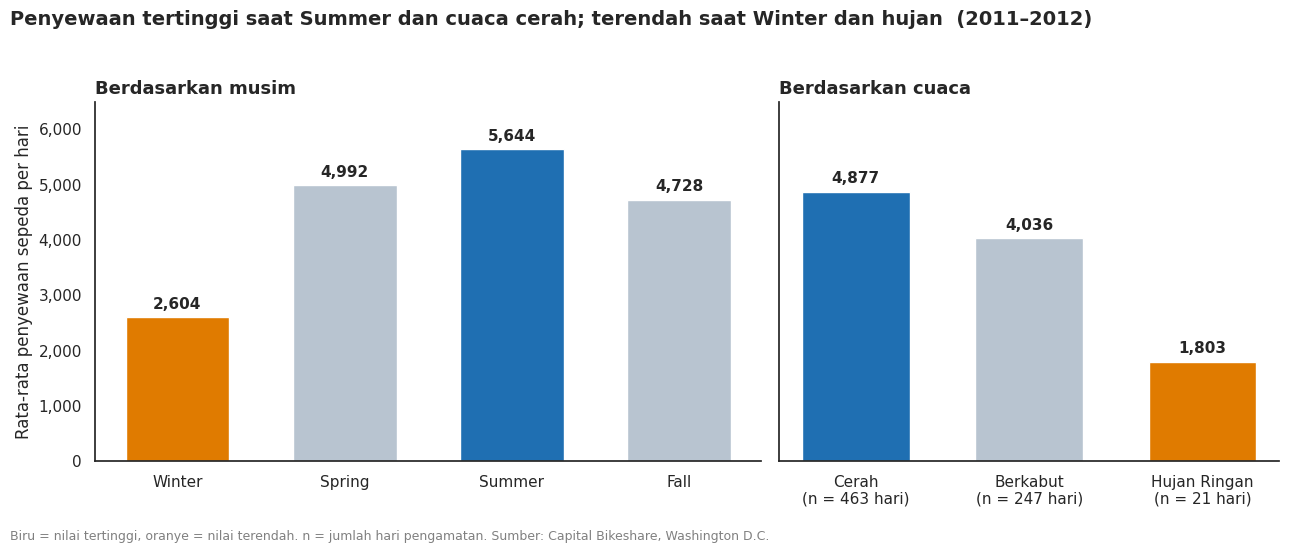

In [75]:
def draw_bars(ax, values, xlabels, title):
    # Biru = tertinggi, oranye = terendah, abu-abu = lainnya; sumbu y dimulai dari 0
    colors = [HIGHLIGHT if v == values.max() else ACCENT if v == values.min() else BASE for v in values]
    bars = ax.bar(xlabels, values, color=colors, width=0.62)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], padding=4, fontsize=11, fontweight="bold")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.spines[["top", "right"]].set_visible(False)

season_mean = day_df.groupby("season", observed=False)["cnt"].mean()
weather_mean = day_df.groupby("weather", observed=True)["cnt"].mean()
weather_n = day_df.groupby("weather", observed=True)["cnt"].size()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, gridspec_kw={"width_ratios": [4, 3]})
draw_bars(axes[0], season_mean.values, season_mean.index.astype(str), "Berdasarkan musim")
draw_bars(axes[1], weather_mean.values,
          [f"{w}\n(n = {n} hari)" for w, n in zip(weather_mean.index.astype(str), weather_n)],
          "Berdasarkan cuaca")
axes[0].set_ylabel("Rata-rata penyewaan sepeda per hari")
axes[0].set_ylim(0, season_mean.max() * 1.15)   # satu skala y bersama (mulai dari 0) agar kedua panel sebanding
fig.suptitle("Penyewaan tertinggi saat Summer dan cuaca cerah; terendah saat Winter dan hujan  (2011–2012)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
fig.text(0.01, -0.03, "Biru = nilai tertinggi, oranye = nilai terendah. n = jumlah hari pengamatan. Sumber: Capital Bikeshare, Washington D.C.",
         fontsize=9, color="gray")
plt.tight_layout()
plt.show()

**Insight:**
- **Musim:** rata-rata penyewaan tertinggi terjadi pada **Summer (5.644/hari)**, terendah pada **Winter (2.604/hari)**. Summer **117% lebih tinggi** dari Winter (atau Winter 54% lebih rendah).
- **Cuaca:** hari **Cerah (4.877/hari)** menghasilkan penyewaan tertinggi, sedangkan **Hujan Ringan (1.803/hari)** terendah, yaitu **63% lebih rendah** dari hari cerah. Cuaca berkabut masih menyisakan sekitar 83% dari penyewaan hari cerah.
- Spring (4.992) dan Fall (4.728) berada di level yang mirip, sehingga lonjakan permintaan terutama terjadi saat keluar dari Winter.
- Pola ini **konsisten pada 2011 maupun 2012** (berkabut turun 16-17%, hujan ringan turun 55-65%), sehingga bukan kebetulan satu tahun saja.
- Catatan: kategori Hujan Ringan hanya berisi 21 hari, sehingga angkanya perlu dibaca sebagai indikasi kuat, bukan nilai yang presisi.

### Pertanyaan 2: Pada jam berapa puncak penyewaan terjadi pada hari kerja dibandingkan akhir pekan/libur (2011–2012)?

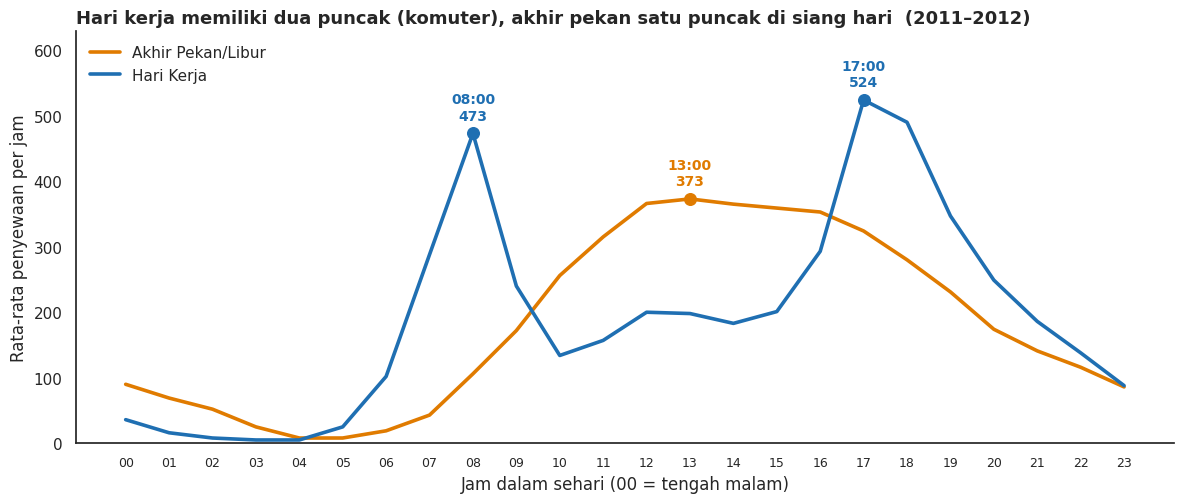

In [76]:
fig, ax = plt.subplots(figsize=(12, 5.2))
warna = {"Hari Kerja": HIGHLIGHT, "Akhir Pekan/Libur": ACCENT}

for tipe in hourly.columns:
    s = hourly[tipe]
    ax.plot(s.index, s.values, color=warna[tipe], lw=2.6, label=tipe)
    puncak = [s.idxmax()] if tipe != "Hari Kerja" else [s[s.index < 12].idxmax(), s[s.index >= 12].idxmax()]
    for h in puncak:
        ax.scatter(h, s[h], color=warna[tipe], s=70, zorder=3)
        ax.annotate(f"{h:02d}:00\n{s[h]:,.0f}", (h, s[h]), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=10, fontweight="bold", color=warna[tipe])

ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)], fontsize=9)
ax.set_xlabel("Jam dalam sehari (00 = tengah malam)")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_ylim(0, hourly.values.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=11)
ax.set_title("Hari kerja memiliki dua puncak (komuter), akhir pekan satu puncak di siang hari  (2011–2012)",
             loc="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- **Hari kerja:** dua puncak yang tajam pada **08:00 (rata-rata 473 penyewaan/jam)** dan **17:00 (524/jam)** yang mencerminkan pola berangkat dan pulang kerja. Di antara kedua puncak, penyewaan turun ke kisaran sekitar 135-200/jam, dan hampir tidak ada aktivitas pada 02:00-04:00 (kurang dari 10/jam).
- **Akhir pekan/libur:** satu puncak landai pada **13:00 (373/jam)** dengan penyewaan di atas 300/jam sepanjang 11:00-17:00, dan naik bertahap sejak pagi hari (tanpa lonjakan jam sibuk seperti hari kerja).
- Puncak sore hari kerja **sekitar 40% lebih tinggi** dibanding puncak akhir pekan, sehingga jam 07:00-09:00 dan 16:00-19:00 pada hari kerja adalah periode dengan tekanan ketersediaan sepeda paling besar.

### Pertanyaan 3: Berapa pertumbuhan penyewaan 2012 dibandingkan 2011 dan pada bulan apa pertumbuhan serta puncak terjadi?

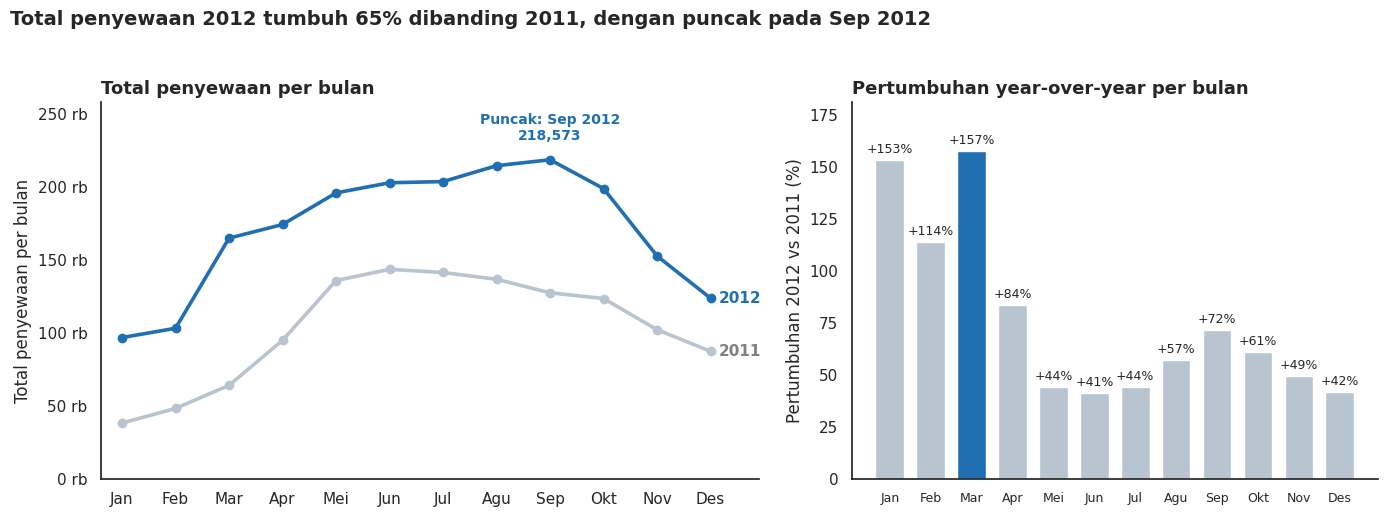

In [77]:
bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
growth = monthly["pertumbuhan_yoy_%"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 2.4]})

# Kiri: total penyewaan per bulan
ax = axes[0]
ax.plot(monthly.index, monthly[2011], color=BASE, lw=2.6, marker="o", label="2011")
ax.plot(monthly.index, monthly[2012], color=HIGHLIGHT, lw=2.6, marker="o", label="2012")
ax.text(12.15, monthly[2011].iloc[-1], "2011", color="gray", va="center", fontsize=11, fontweight="bold")
ax.text(12.15, monthly[2012].iloc[-1], "2012", color=HIGHLIGHT, va="center", fontsize=11, fontweight="bold")
pk = monthly[2012].idxmax()
ax.annotate(f"Puncak: {bulan[pk - 1]} 2012\n{monthly[2012][pk]:,.0f}", (pk, monthly[2012][pk]),
            xytext=(0, 14), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color=HIGHLIGHT)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(bulan)
ax.set_xlim(0.6, 12.9); ax.set_ylim(0, monthly[2012].max() * 1.18)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:,.0f} rb"))
ax.set_ylabel("Total penyewaan per bulan")
ax.set_title("Total penyewaan per bulan", loc="left", fontsize=13, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)

# Kanan: pertumbuhan YoY per bulan
ax = axes[1]
warna_bar = [HIGHLIGHT if v == growth.max() else BASE for v in growth.values]
bars = ax.bar(range(1, 13), growth.values, color=warna_bar, width=0.7)
ax.bar_label(bars, labels=[f"+{v:.0f}%" for v in growth.values], padding=3, fontsize=9)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(bulan, fontsize=9)
ax.set_ylim(0, growth.max() * 1.15)
ax.set_ylabel("Pertumbuhan 2012 vs 2011 (%)")
ax.set_title("Pertumbuhan year-over-year per bulan", loc="left", fontsize=13, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)

total_growth = total[2012] / total[2011] - 1
fig.suptitle(f"Total penyewaan 2012 tumbuh {total_growth:.0%} dibanding 2011, dengan puncak pada {bulan[pk - 1]} 2012",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
- Total penyewaan 2012 sebesar 2.049.576, **tumbuh 64,9%** dari 1.243.103 pada 2011, dan seluruh bulan tumbuh minimal 41%.
- Pertumbuhan **tertinggi pada Maret (+157%)** dan Januari (+153%), lalu melambat menjadi sekitar +41% hingga +44% pada Mei-Juli dan Desember. Pertumbuhan awal tahun yang sangat tinggi sebagian disebabkan basis 2011 yang masih kecil.
- Pola musiman sama di kedua tahun: permintaan naik dari Januari, mencapai level tinggi pada Mei-September, lalu turun menjelang akhir tahun. **Puncak 2012 terjadi pada September (218.573)**, sedangkan puncak 2011 pada Juni (143.512).

## Analisis Lanjutan (Opsional)

Analisis lanjutan yang digunakan adalah **Clustering tanpa machine learning** dengan dua metode:

1. **Binning (`pd.cut`)** pada suhu harian. Tujuannya mengetahui pada rentang suhu berapa penyewaan paling tinggi, sehingga operator bisa memanfaatkan prakiraan cuaca untuk memperkirakan permintaan.
2. **Manual grouping berbasis kuantil (`pd.qcut`)** untuk mengelompokkan hari menjadi segmen permintaan *Rendah*, *Sedang*, dan *Tinggi* (masing-masing sepertiga hari). Tujuannya membuat profil hari-hari permintaan tinggi (musim, suhu, tipe hari, proporsi pengguna casual) agar strategi armada dan promosi dapat disesuaikan.

Teknik ini relevan karena dataset berisi variabel numerik berkelanjutan (suhu dan jumlah penyewaan) yang mudah dikelompokkan berdasarkan aturan bisnis.

### Binning suhu harian

In [78]:
labels_suhu = ["Dingin (<10°C)", "Sejuk (10–20°C)", "Hangat (20–30°C)", "Panas (≥30°C)"]
day_df["kelompok_suhu"] = pd.cut(day_df["temp_c"], bins=[-np.inf, 10, 20, 30, np.inf], labels=labels_suhu, right=False)

temp_stats = (day_df.groupby("kelompok_suhu", observed=False)["cnt"]
              .agg(jumlah_hari="count", rata_rata="mean").round(0))
temp_stats

,jumlah_hari,rata_rata
kelompok_suhu,,
Dingin (<10°C),60,1678.0
Sejuk (10–20°C),299,3692.0
Hangat (20–30°C),300,5662.0
Panas (≥30°C),72,5410.0


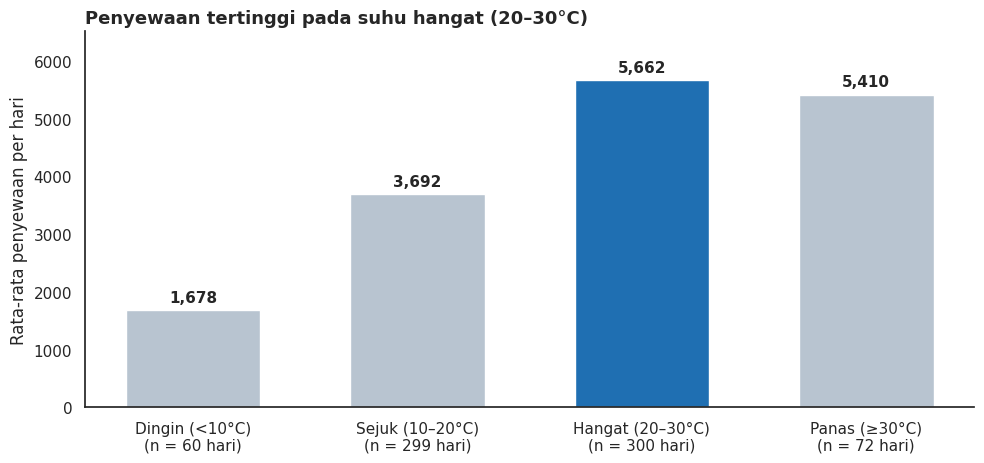

In [79]:
fig, ax = plt.subplots(figsize=(10, 4.8))
vals = temp_stats["rata_rata"]
colors = [HIGHLIGHT if v == vals.max() else BASE for v in vals]
bars = ax.bar([f"{k}\n(n = {n} hari)" for k, n in zip(vals.index, temp_stats["jumlah_hari"])], vals, color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in vals], padding=4, fontsize=11, fontweight="bold")
ax.set_ylim(0, vals.max() * 1.15)
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_title("Penyewaan tertinggi pada suhu hangat (20–30°C)", loc="left", fontsize=13, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Segmentasi hari berdasarkan tingkat permintaan

In [80]:
day_df["segmen_permintaan"] = pd.qcut(day_df["cnt"], q=3, labels=["Rendah", "Sedang", "Tinggi"])
day_df["persen_casual"] = day_df["casual"] / day_df["cnt"] * 100

profil = day_df.groupby("segmen_permintaan", observed=False).agg(
    jumlah_hari=("cnt", "size"),
    penyewaan_min=("cnt", "min"),
    penyewaan_maks=("cnt", "max"),
    rata_suhu_c=("temp_c", "mean"),
    rata_kelembapan=("hum_pct", "mean"),
    rata_angin_kmh=("windspeed_kmh", "mean"),
    persen_casual=("persen_casual", "mean"),
).round(1)
profil["persen_hari_kerja"] = (day_df.assign(kerja=day_df["day_type"] == "Hari Kerja")
                               .groupby("segmen_permintaan", observed=False)["kerja"].mean() * 100).round(1)
profil

,jumlah_hari,penyewaan_min,penyewaan_maks,rata_suhu_c,rata_kelembapan,rata_angin_kmh,persen_casual,persen_hari_kerja
segmen_permintaan,,,,,,,,
Rendah,244,22,3740,13.7,63.5,14.3,13.9,62.3
Sedang,244,3744,5312,22.9,64.6,12.2,18.5,73.0
Tinggi,243,5315,8714,24.4,60.5,11.8,20.3,70.0


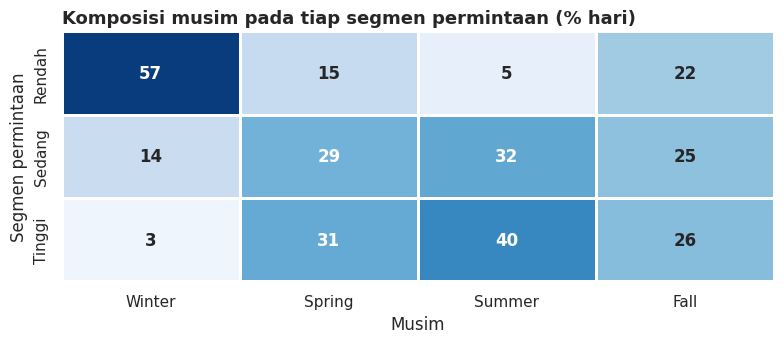

In [81]:
komposisi = (pd.crosstab(day_df["segmen_permintaan"], day_df["season"], normalize="index") * 100).round(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(komposisi, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=1, linecolor="white",
            annot_kws={"fontsize": 12, "fontweight": "bold"}, ax=ax, vmin=0, vmax=60)
ax.set_xlabel("Musim"); ax.set_ylabel("Segmen permintaan")
ax.set_title("Komposisi musim pada tiap segmen permintaan (% hari)", loc="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- **Binning suhu:** penyewaan tertinggi pada suhu **hangat 20-30°C (5.662/hari, 300 hari)**. Pada suhu panas ≥30°C (72 hari) turun sedikit menjadi 5.410 (sekitar 4% lebih rendah), sedangkan pada suhu dingin <10°C hanya **1.678/hari**, atau sekitar 70% lebih rendah dari suhu hangat.
- **Segmentasi permintaan:** masing-masing sepertiga hari dikelompokkan menjadi Rendah (22-3.740 penyewaan), Sedang (3.744-5.312), dan Tinggi (5.315-8.714).
  - Segmen **Rendah** didominasi **Winter (57% harinya)** dengan suhu rata-rata 13,7°C dan angin paling kencang (14,3 km/jam).
  - Segmen **Tinggi** didominasi **Summer (40%)** dengan suhu rata-rata 24,4°C dan angin paling tenang (11,8 km/jam); hanya 3% harinya jatuh pada Winter.
  - Proporsi hari kerja relatif sama di semua segmen (62-73%), sehingga **musim dan suhu, bukan tipe hari, yang membedakan hari ramai dan sepi**.
  - Porsi pengguna casual naik dari 13,9% (Rendah) ke 20,3% (Tinggi), menandakan pengguna casual lebih responsif terhadap cuaca yang baik.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Musim dan cuaca sangat memengaruhi permintaan. Rata-rata penyewaan tertinggi pada **Summer (5.644/hari)** dan terendah pada **Winter (2.604/hari)**, selisih **117%**. Berdasarkan cuaca, hari **Cerah (4.877/hari)** menghasilkan penyewaan **63% lebih tinggi** dibanding hari **Hujan Ringan (1.803/hari)**. Analisis lanjutan mendukung hal ini: penyewaan tertinggi terjadi pada suhu 20-30°C dan terendah pada suhu di bawah 10°C.
- **Conclusion pertanyaan 2:** Pola jam berbeda jelas antara tipe hari. **Hari kerja** memiliki dua puncak komuter pada **08:00 (473/jam)** dan **17:00 (524/jam)**, sedangkan **akhir pekan/libur** hanya memiliki satu puncak pada **13:00 (373/jam)**. Hari kerja didominasi pengguna terdaftar (86,8%), sedangkan pengguna casual mencapai 31,7% pada akhir pekan/libur.
- **Conclusion pertanyaan 3:** Total penyewaan 2012 **tumbuh 64,9%** dibanding 2011 (1.243.103 menjadi 2.049.576), dengan pertumbuhan bulanan tertinggi pada **Maret (+157%)**. Pola musiman konsisten di kedua tahun dan **puncak 2012 terjadi pada September (218.573 penyewaan)**, sedangkan titik terendah selalu pada Januari.

**Rekomendasi Action Item:**
- **Redistribusi armada berbasis jam (hari kerja):** pastikan stok sepeda dan proses redistribusi selesai sebelum **07:00** dan **16:00**, karena puncak 08:00 dan 17:00 adalah periode permintaan tertinggi (hingga 524 penyewaan/jam).
- **Jadwalkan pemeliharaan di jam sepi dan musim sepi:** lakukan servis rutin pada **00:00-05:00** (kurang dari 40 penyewaan/jam pada hari kerja) dan pada musim **Winter** atau hari hujan, saat permintaan turun hingga 54-63%.
- **Promosi pengguna casual di akhir pekan:** buat promo tengah hari (**11:00-17:00**, saat penyewaan di atas 300/jam) dan tawarkan paket konversi *casual menjadi member*, karena casual mencapai 31,7% penyewaan pada akhir pekan/libur.
- **Promosi pendorong permintaan di musim sepi:** tawarkan diskon atau paket langganan pada Winter dan hari berkabut, serta kampanye khusus saat suhu berada di rentang ideal 20-30°C.
- **Perencanaan kapasitas tahunan:** tambah armada sebelum **Maret-Mei** (fase pertumbuhan tercepat) dan siapkan kapasitas puncak pada **Mei-September**; gunakan prakiraan suhu dan cuaca harian sebagai input penyesuaian jumlah sepeda yang disebar.
- **Peningkatan kualitas data:** perbaiki pencatatan sensor (kelembapan 0% dan angin 0) serta catat jam tanpa transaksi secara eksplisit agar analisis ke depan lebih akurat.